## Setup

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
from google.colab import drive, userdata
drive.mount("/content/drive")

import os
token = userdata.get("GITHUB_TOKEN")
REPO = "/content/mamba-dsr"
DRIVE = "/content/drive/MyDrive/Colab Notebooks/MTP"
OLD_CKPT = f"{DRIVE}/checkpoints"          # read only
NEW_CKPT = f"{DRIVE}/checkpoints_retrain"  # this run's backups

if not os.path.exists(f"{REPO}/.git"):
    !git init -q {REPO} && git -C {REPO} remote add origin https://{token}@github.com/yt-1-dev/mamba-dsr.git
!git -C {REPO} fetch -q origin main && git -C {REPO} checkout -q -f -B main origin/main && git -C {REPO} log --oneline -1

%cd {REPO}
!mkdir -p checkpoints results "{NEW_CKPT}"
!cp -n "{OLD_CKPT}/pretrain_best.pt" checkpoints/
# resume after a disconnect: restore this run's checkpoints
!rsync -ah "{NEW_CKPT}/" checkpoints/
!bash convert.sh

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
Mounted at /content/drive
99102d1 (HEAD -> main, origin/main) code cleanup
/content/mamba-dsr
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
[NbConvertApp] Converting notebook colab_train.ipynb to python
[NbConvertApp] Writing 4588 bytes to python_files/colab_train.py
[NbConvertApp] Converting notebook DataLoaders.ipynb to python
[NbConvertApp] Writing 11843 bytes to python_files/DataLoaders.py
[NbConvertApp] Converting notebook jasper.ipynb to python
[NbConvertApp] Writing 23405 bytes to python_files/jasper.py
[NbConvertApp] Converting notebook main.ipynb to python
[NbConvertApp] Writing 76285 bytes to python_files/main.py
[NbConvertApp] Converting notebook MambaBlocks.ipynb to python
[NbConvertApp] Writing 7197 bytes to python_files/MambaBlocks.py
[NbConvertApp] Converting notebook preprocess.ipynb to python
[NbConvertApp] Writing 9510 bytes to python_files/preprocess.py
[NbConvertApp] Conv

In [ ]:
%cd /content
!7z x "{DRIVE}/data-2.zip" -mmt=on -aos
%cd {REPO}

/content

7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:12 OPEN_MAX:1048576

Scanning the drive for archives:
  0M Scan /content/drive/MyDrive/Colab Notebooks/MTP/                                                     1 file, 27113727592 bytes (26 GiB)

Extracting archive: /content/drive/MyDrive/Colab Notebooks/MTP/data-2.zip
  0% 4096 Open               26% 110592 Open                 36% 151552 Open                 66% 274432 Open                 70% 290816 Open                 93% 385024 Open                --
Path = /content/drive/MyDrive/Colab Notebooks/MTP/data-2.zip
Type = zip
Physical Size = 27113727592
64-bit = +
Characteristics = Zi

In [ ]:
!pip install -q torch==2.9.1 torchaudio==2.9.1 torchvision==0.24.1 --index-url https://download.pytorch.org/whl/cu128

In [ ]:
import sys, torch
tv = ".".join(torch.__version__.split("+")[0].split(".")[:2])
cu = torch.version.cuda.split(".")[0]
py = f"cp{sys.version_info.major}{sys.version_info.minor}"
tag = f"cu{cu}torch{tv}cxx11abiTRUE-{py}-{py}-linux_x86_64"
print("torch", torch.__version__, "->", tag)

CC = f"https://github.com/Dao-AILab/causal-conv1d/releases/download/v1.7.0/causal_conv1d-1.7.0+{tag}.whl"
MS = f"https://github.com/state-spaces/mamba/releases/download/v2.3.2.post1/mamba_ssm-2.3.2.post1+{tag}.whl"
TORCHCODEC = {"2.8": "0.7", "2.9": "0.9", "2.10": "0.10"}.get(tv)
extra = f"torchcodec=={TORCHCODEC}" if TORCHCODEC else ""

!pip install -q {CC} {MS} "speechbrain>=1.0.0" soundfile kaggle {extra}

from mamba_ssm import Mamba3
print("mamba_ssm ok")

torch 2.9.1+cu128 -> cu12torch2.9cxx11abiTRUE-cp313-cp313-linux_x86_64
mamba_ssm ok


In [ ]:
# NeMo for Jasper, with the training stack pinned
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "triton", "numpy",
        "mamba-ssm", "causal-conv1d", "speechbrain", "huggingface-hub",
        "soundfile", "scipy", "librosa"]
pins = []
for name in KEEP:
    try:
        pins.append(f"{name}=={md.version(name)}")
    except md.PackageNotFoundError:
        pass
open("/tmp/keep.txt", "w").write("\n".join(pins))
!{sys.executable} -m pip install -q -c /tmp/keep.txt "nemo_toolkit[asr]" jiwer xlrd

import speechbrain, nemo.collections.asr as nemo_asr
print("torch", torch.__version__, "| speechbrain", speechbrain.__version__, "| NeMo OK")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


torch 2.9.1+cu128 | speechbrain 1.1.2 | NeMo OK


In [ ]:
import shutil, subprocess
from pathlib import Path
import pandas as pd, jiwer
import torch

# Ensure PyTorch starts with a correctly initialized indexed CUDA device
if torch.cuda.is_available():
    torch.cuda.set_device(0)

# Patch torch.cuda.device to handle None indices (fixes mamba_ssm on torch 2.9+)
_orig_cuda_device = torch.cuda.device
class PatchedCudaDevice(_orig_cuda_device):
    def __init__(self, device=None):
        if device is None:
            device = torch.cuda.current_device()
        super().__init__(device)
torch.cuda.device = PatchedCudaDevice

SKIP = ("set_checkpoint_mode(", "train, test = load_dataloaders", "print(len(train))")

def load_src(*names):
    # exec python_files/<name>.py without its top-level calls
    for n in names:
        p = Path(f"{REPO}/python_files/{n}.py")
        src = "\n".join(l for l in p.read_text().splitlines()
                        if not l.startswith(SKIP) and not l.lstrip().startswith("%"))

        # Replace generic 'cuda' device definitions with 'cuda:0' to prevent exchangeDevice index None errors
        src = src.replace('"cuda"', '"cuda:0"').replace("'cuda'", "'cuda:0'")
        src = src.replace('.cuda()', '.to("cuda:0")')

        exec(compile(src, str(p), "exec"), globals())

def backup():
    subprocess.run(["rsync", "-ah", "./checkpoints/", f"{NEW_CKPT}/"], check=True)
    subprocess.run(["rsync", "-ah", "./results/", f"{NEW_CKPT}/results/"], check=True)

def stage(mode, ckpt, **cfg):
    # fresh MODE_CONFIG, apply overrides, train, back up
    load_src("main")
    MODE_CONFIG[mode].update(cfg)
    print(mode, MODE_CONFIG[mode])
    try:
        train(mode, ckpt, "cuda:0")
    finally:
        backup()

def snap(src, dst):
    shutil.copy(f"checkpoints/{src}", f"checkpoints/{dst}")
    backup()

STATS = {}
def add_stats(name, df, col="hyp_reconstructed"):
    h, r = df[col].fillna(""), df["reference"]
    STATS[name] = {"exact_%": round(100 * (h == r).mean(), 1),
                   "CER": round(100 * jiwer.cer(r.tolist(), h.tolist()), 1),
                   "WER": round(100 * jiwer.wer(r.tolist(), h.tolist()), 1),
                   "empty_%": round(100 * (h == "").mean(), 1)}
    print(pd.DataFrame(STATS).T)

load_src("main")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


hyperparams.yaml:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


embedding_model.ckpt: reconstructing file:   0%|          |  0.00B / 83.3MB            

embedding_model.ckpt: downloading bytes:           |  0.00B            

INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


... (9 outputs left out)

generator.ckpt: reconstructing file:   0%|          |  0.00B / 55.8MB            

generator.ckpt: downloading bytes:           |  0.00B            

INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: generator


Forward pass OK
Mode: pretrain — 8,846,548 / 45,459,926 params trainable
../data/processed/libreTTS/ /content/mamba-dsr


## 0. Pretrain (optional)

In [ ]:
# only to rebuild pretrain_best.pt (colab: 10 epochs)
RETRAIN_PRETRAIN = True
if RETRAIN_PRETRAIN:
    stage("pretrain", None, epochs=10, batch_size=16, eval_interval=500)

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

Forward pass OK
Mode: pretrain — 8,846,548 / 45,459,926 params trainable
../data/processed/libreTTS/ /content/mamba-dsr
pretrain {'lr': 0.0003, 'batch_size': 16, 'epochs': 10, 'warmup_steps': 5000, 'grad_clip': 1.0, 'log_interval': 50, 'eval_interval': 500, 'save_interval': 5000}
  dataset: libre-tts


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


  29551 train / 1555 val samples
246 Speakers
  codebook: 4 groups x 512 codes x 32 dims


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch generator.ckpt: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/generator.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: generator


Mode: pretrain — 8,865,382 / 45,478,760 params trainable
  Computing speaker embeddings for 246 speakers

Starting training: 18460 steps (10 epochs)
  Batch size: 16
  Learning rate: 0.0003
  Warmup: 5000 steps
  Grad clip: 1.0
  Start Epoch: 0
  Start Step: 0
  Best Metric : inf
  [VAL] step 500 | val/mel_loss: 9.4770 | val/vq_loss: 1.7776 | val/adv_loss: 5.4919 | val/total_loss: 11.8038 | val/perplexity: 36.3271
{'train/mel_loss': 9.54190444946289, 'train/vq_loss': 2.995063304901123, 'train/adv_loss': 5.517717361450195, 'train/total_loss': 13.088740348815918, 'train/perplexity': 395.9114990234375, 'train/active_ratio': 0.9599609375, 'train/grad_norm': 3.139573812484741, 'train/lr': 2.9999999999999997e-05}
  [BEST] New best val loss: 9.4770 → ./checkpoints/pretrain_best.pt
  [VAL] step 1000 | val/mel_loss: 3.7930 | val/vq_loss: 1.8724 | val/adv_loss: 5.3975 | val/total_loss: 6.2051 | val/perplexity: 43.6838
{'train/mel_loss': 3.6602725982666016, 'train/vq_loss': 3.0322163105010986, 't

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Tokenizer

In [ ]:
# plain reconstruction tokenizer (colab default: 15 epochs)
stage("tokenizer", "./checkpoints/pretrain_best.pt", consistency_weight=0.0, epochs=15, eval_interval=500)
snap("tokenizer_best.pt", "tokenizer_plain.pt")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

Forward pass OK
Mode: pretrain — 8,846,548 / 45,459,926 params trainable
../data/processed/libreTTS/ /content/mamba-dsr
tokenizer {'adv_weight': 0.0, 'consistency_weight': 0.0, 'lr': 0.0003, 'batch_size': 16, 'epochs': 15, 'warmup_steps': 2000, 'grad_clip': 1.0, 'log_interval': 50, 'eval_interval': 500, 'save_interval': 2000}
  dataset: codes2mel


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'


  Codes2MelDataset: 31106 LibriTTS + 46265 UA control utterances, 259 speakers
  73503 train / 3868 val samples
259 Speakers
  codebook: 4 groups x 512 codes x 32 dims


INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch generator.ckpt: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/generator.ckpt'
INFO:speechbrain.

Mode: tokenizer — 8,867,059 / 45,480,437 params trainable
  Skipped shape-mismatched: ['speaker_adversary.classifier.3.bias', 'speaker_adversary.classifier.3.weight']
  WARNING  missing=['reference_emb', 'speaker_adversary.classifier.3.weight', 'speaker_adversary.classifier.3.bias', 'code_heads.0.weight', 'code_heads.0.bias', 'code_heads.1.weight', 'code_heads.1.bias', 'code_heads.2.weight', 'code_heads.2.bias', 'code_heads.3.weight', 'code_heads.3.bias']  unexpected=[]
  Loaded weights from ./checkpoints/pretrain_best.pt (mode: pretrain → tokenizer)
  Resetting step, epoch, metric, optimizer, scheduler
  Checkpoint is from a different dataset: resetting step/metric, reusing shared speaker embs
  Computing speaker embeddings for 13 speakers

Starting training: 68895 steps (15 epochs)
  Batch size: 16
  Learning rate: 0.0003
  Warmup: 2000 steps
  Grad clip: 1.0
  Start Epoch: 0
  Start Step: 0
  Best Metric : inf
  [VAL] step 500 | val/mel_loss: 2.2412 | val/vq_loss: 1.6918 | val/adv_l

KeyboardInterrupt: 

In [ ]:
snap("tokenizer_best.pt", "tokenizer_plain.pt")

In [ ]:
# consistency fine-tune; relabel the copy so it starts fresh instead of resuming
snap("tokenizer_plain.pt", "tokenizer_init.pt")
set_checkpoint_mode("checkpoints/tokenizer_init.pt", "pretrain")
stage("tokenizer", "./checkpoints/tokenizer_init.pt", consistency_weight=0.1, epochs=5, eval_interval=500)

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'


  tokenizer_init.pt: mode 'tokenizer' → 'pretrain'


INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch generator.ckpt: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/generator.ckpt'
INFO:speechbrain.

Forward pass OK
Mode: pretrain — 8,846,548 / 45,459,926 params trainable
../data/processed/libreTTS/ /content/mamba-dsr
tokenizer {'adv_weight': 0.0, 'consistency_weight': 0.1, 'lr': 0.0003, 'batch_size': 16, 'epochs': 5, 'warmup_steps': 2000, 'grad_clip': 1.0, 'log_interval': 50, 'eval_interval': 500, 'save_interval': 2000}
  dataset: tokenizer-pairs
  Codes2MelDataset: 31106 LibriTTS + 46265 UA control utterances, 259 speakers


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


  consistency pairs: 46265 utterances, 6630 takes, 355 words
  73503 train / 3868 val samples
259 Speakers
  codebook: 4 groups x 512 codes x 32 dims


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch generator.ckpt: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/generator.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: generator


Mode: tokenizer — 8,867,059 / 45,480,437 params trainable
  consistency loss on, weight 0.1
  Loaded weights from ./checkpoints/tokenizer_init.pt (mode: pretrain → tokenizer)
  Resetting step, epoch, metric, optimizer, scheduler

Starting training: 22965 steps (5 epochs)
  Batch size: 16
  Learning rate: 0.0003
  Warmup: 2000 steps
  Grad clip: 1.0
  Start Epoch: 0
  Start Step: 0
  Best Metric : inf
  [VAL] step 500 | val/mel_loss: 1.4368 | val/vq_loss: 1.6057 | val/adv_loss: 5.6453 | val/total_loss: 3.1284 | val/perplexity: 18.4165 | val/cons_loss: 0.8597
{'train/mel_loss': 1.181113362312317, 'train/vq_loss': 3.114321231842041, 'train/adv_loss': 5.537471771240234, 'train/total_loss': 4.370006084442139, 'train/perplexity': 367.0372009277344, 'train/active_ratio': 0.9794921875, 'train/grad_norm': 1.2556228637695312, 'train/lr': 7.5e-05, 'train/cons_loss': 0.7457172870635986}
  [BEST] New best val loss: 1.4368 → ./checkpoints/tokenizer_best.pt
  [VAL] step 1000 | val/mel_loss: 1.5433 | 

In [ ]:
# tokenizer stats: codes-only gate, cross-take agreement, codebook health
load_src("main", "jasper")
gate = codes2mel_gate("checkpoints/tokenizer_best.pt")
code_agreement_check("checkpoints/tokenizer_best.pt", merge_classes=(None, 256, 128, 64))

st = torch.load("checkpoints/tokenizer_best.pt", map_location="cpu", weights_only=False)["model_state_dict"]
for g in range(4):
    E = st[f"vq.quantizers.{g}.embedding"]
    p = st[f"vq.quantizers.{g}.ema_cluster_size"]; p = p / p.sum()
    D = torch.cdist(E, E); med = D[D > 0].median(); D.fill_diagonal_(float("inf"))
    nn_d = D.min(1).values / med
    ppl = torch.exp(-(p * (p + 1e-12).log()).sum())
    print(f"group {g}: perplexity {ppl:.0f}/512 | under 0.1% use {(p < 1e-3).sum().item()} | "
          f"near-twins {(nn_d < 0.15).sum().item()}")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

Forward pass OK
Mode: pretrain — 8,846,548 / 45,459,926 params trainable
../data/processed/libreTTS/ /content/mamba-dsr


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

Loaded checkpoints/tokenizer_best.pt (skip off, VQ codes) (step 4500, mode tokenizer, best val 1.2152767515182494)
Loaded 455 word labels


gate:   0%|          | 0/255 [00:00<?, ?it/s]

[NeMo I 2026-11-10 14:44:40 cloud:68] Downloading from: https://api.ngc.nvidia.com/v2/models/nvidia/nemo/stt_en_jasper10x5dr/versions/1.0.0rc1/files/stt_en_jasper10x5dr.nemo to /root/.cache/torch/NeMo/NeMo_3.0.0/stt_en_jasper10x5dr/856ae08d5c4bd78b5e27f696e96f7aab/stt_en_jasper10x5dr.nemo
[NeMo I 2026-11-10 14:44:45 common:1122] Instantiating model from pre-trained checkpoint


... (2 outputs left out)

Transcribing: 100%|██████████| 16/16 [00:03<00:00,  5.17it/s]



CF02 B2 M5: 255 words
  direct  exact  63.1%   empty   2.4%   CER  17.8%
  codes   exact  28.2%   empty   8.6%   CER  50.0%


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

CF02 B1 vs B3 (M5): 155 words, 18739 aligned code frames
      raw 512 codes: exact  17.7%   chance  4.2%   above chance  14.1%   near-5  40.1%
   merged 256 codes: exact  21.7%   chance  6.3%   above chance  16.5%
   merged 128 codes: exact  37.5%   chance 18.4%   above chance  23.4%
    merged 64 codes: exact  47.8%   chance 27.0%   above chance  28.6%
group 0: perplexity 374/512 | under 0.1% use 142 | near-twins 324
group 1: perplexity 363/512 | under 0.1% use 146 | near-twins 274
group 2: perplexity 363/512 | under 0.1% use 139 | near-twins 274
group 3: perplexity 362/512 | under 0.1% use 150 | near-twins 273


## 2. Recognizer

In [ ]:
# target codes live in the local data files: re-run after a runtime restart
load_src("main")
precompute_target_codes("./checkpoints/tokenizer_best.pt")
precompute_multi_target_codes("./checkpoints/tokenizer_best.pt")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

Forward pass OK
Mode: pretrain — 8,846,548 / 45,459,926 params trainable
../data/processed/libreTTS/ /content/mamba-dsr


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

target codes:   0%|          | 0/66739 [00:00<?, ?it/s]

{'encoded': 66739, 'already': 0, 'no_dtw_target': 0}


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

  2040 reference takes from CF02, CF03, CF04, CF05 (355 words)


multi-ref codes:   0%|          | 0/44254 [00:00<?, ?it/s]

{'encoded': 44254, 'already': 0, 'no_target_codes': 0, 'refs_total': 239354, 'mean_extra_refs': 5.41}


In [ ]:
# colab: 3 epochs
stage("recognizer", "./checkpoints/tokenizer_best.pt", epochs=3, eval_interval=500, merge_classes=None)
snap("recognizer_best.pt", "recognizer_raw.pt")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

Forward pass OK
Mode: pretrain — 8,846,548 / 45,459,926 params trainable
../data/processed/libreTTS/ /content/mamba-dsr
recognizer {'lr': 0.0002, 'batch_size': 16, 'epochs': 3, 'warmup_steps': 1000, 'grad_clip': 1.0, 'log_interval': 50, 'eval_interval': 500, 'save_interval': 2000, 'head_layers': 2, 'multi_ref': True, 'merge_classes': None, 'soft_tau': 0.5, 'head_dropout': 0.1, 'freeze_lower_encoder': False, 'specaug': True}
  dataset: ua-speech-multi
  39231 train / 2050 val samples
14 Speakers


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


  codebook: 4 groups x 512 codes x 32 dims


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch generator.ckpt: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/generator.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: generator


Mode: recognizer — 8,339,456 / 47,347,776 params trainable
  recognizer: head_layers=2, soft_tau=0.5, head_dropout=0.1, freeze_lower_encoder=False, specaug=True -> 8,339,456 params trainable
  Skipped shape-mismatched: ['speaker_adversary.classifier.3.bias', 'speaker_adversary.classifier.3.weight']
  WARNING  missing=['speaker_adversary.classifier.3.weight', 'speaker_adversary.classifier.3.bias', 'code_trunk.0.norm.weight', 'code_trunk.0.forward_layer.dt_bias', 'code_trunk.0.forward_layer.B_bias', 'code_trunk.0.forward_layer.C_bias', 'code_trunk.0.forward_layer.D', 'code_trunk.0.forward_layer.in_proj.weight', 'code_trunk.0.forward_layer.B_norm.weight', 'code_trunk.0.forward_layer.C_norm.weight', 'code_trunk.0.forward_layer.out_proj.weight', 'code_trunk.0.backward_layer.dt_bias', 'code_trunk.0.backward_layer.B_bias', 'code_trunk.0.backward_layer.C_bias', 'code_trunk.0.backward_layer.D', 'code_trunk.0.backward_layer.in_proj.weight', 'code_trunk.0.backward_layer.B_norm.weight', 'code_trun

## 3. rec2mel

In [ ]:
# colab: 3 epochs
stage("rec2mel", "./checkpoints/recognizer_raw.pt", epochs=3, eval_interval=500)
snap("rec2mel_best.pt", "rec2mel_raw.pt")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

Forward pass OK
Mode: pretrain — 8,846,548 / 45,459,926 params trainable
../data/processed/libreTTS/ /content/mamba-dsr
rec2mel {'lr': 0.0001, 'batch_size': 16, 'epochs': 3, 'warmup_steps': 500, 'grad_clip': 1.0, 'log_interval': 50, 'eval_interval': 500, 'save_interval': 2000, 'specaug': False}
  dataset: ua-speech
  39231 train / 2050 val samples
14 Speakers


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


  codebook: 4 groups x 512 codes x 32 dims


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch generator.ckpt: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/generator.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: generator


Mode: rec2mel — 2,836,848 / 47,347,776 params trainable
  Loaded weights from ./checkpoints/recognizer_raw.pt (mode: recognizer → rec2mel)
  Resetting step, epoch, metric, optimizer, scheduler
  rec2mel: recognizer frozen (2 trunk layers), training injector + decoder on its argmax codes

Starting training: 7353 steps (3 epochs)
  Batch size: 16
  Learning rate: 0.0001
  Warmup: 500 steps
  Grad clip: 1.0
  Start Epoch: 0
  Start Step: 0
  Best Metric : inf
  [VAL] step 500 | val/mel_loss: 2.1690 | val/vq_loss: 0.0000 | val/adv_loss: 0.0000 | val/total_loss: 2.1690 | val/perplexity: 7.2209 | val/ce_loss: 3.6246 | val/code_acc: 0.1836 | val/code_acc_near: 0.4273
{'train/mel_loss': 1.7949048280715942, 'train/vq_loss': 0.0, 'train/adv_loss': 0.0, 'train/total_loss': 1.7949048280715942, 'train/perplexity': 6.768373489379883, 'train/active_ratio': 0.0634765625, 'train/grad_norm': 4.571988105773926, 'train/lr': 0.0001, 'train/ce_loss': 3.5802230834960938, 'train/code_acc': 0.21352313458919525

In [ ]:
load_src("main", "jasper")
df_rec, _ = run_jasper("checkpoints/recognizer_raw.pt", vocode_original=False)
add_stats("original", df_rec, "hyp_original")
add_stats("recognizer", df_rec)

df_r2m, _ = run_jasper("checkpoints/rec2mel_raw.pt", vocode_original=False)
add_stats("recognizer + rec2mel", df_r2m)

# ceiling: true target codes through the decoder
oracle_df, oracle_table = oracle_codes_check("checkpoints/recognizer_raw.pt", original_df=df_rec)
add_stats("oracle", oracle_df, "hyp_oracle")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

Forward pass OK
Mode: pretrain — 8,846,548 / 45,459,926 params trainable
../data/processed/libreTTS/ /content/mamba-dsr


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

Loaded checkpoints/recognizer_raw.pt (skip off, predicted codes) (step 7000, mode recognizer, best val 4.175821723937989)


M05:   0%|          | 0/249 [00:00<?, ?it/s]

  M05: 249 utterances


... (41 outputs left out)

Transcribing: 100%|██████████| 54/54 [00:43<00:00,  1.24it/s]


Oracle (true target codes -> decoder -> HiFi-GAN), B2 M5


,speaker,n_words,WER_original,exact_original,CER_original,empty_original,WER_oracle,exact_oracle,CER_oracle,empty_oracle,rel_WER_reduction_%
0,F02,252,149.6,4.0,88.3,13.1,113.0,11.9,74.2,16.7,24.5
1,F04,229,112.1,21.0,63.9,2.6,94.8,28.4,48.5,7.9,15.4
2,M05,249,147.4,12.9,75.7,8.4,119.9,17.7,62.6,7.2,18.7
3,M07,119,162.0,2.5,92.4,12.6,101.7,24.4,48.2,5.9,37.2
4,ALL,849,140.6,11.0,78.8,8.8,108.5,19.8,59.9,10.0,22.8


Mean of per-speaker relative WER reductions (UNIT-DSR style): 23.9%
                      exact_%   CER    WER  empty_%
original                 11.0  78.8  140.6      8.8
recognizer                2.8  93.5  124.4     31.6
recognizer + rec2mel      3.4  90.5  116.0     31.7
oracle                   19.8  59.9  108.5     10.0


## 4. Merged classes (256)

In [ ]:
snap("recognizer_raw.pt", "recognizer_init.pt")
set_checkpoint_mode("checkpoints/recognizer_init.pt", "tokenizer")
stage("recognizer", "./checkpoints/recognizer_init.pt", epochs=3, eval_interval=500, merge_classes=256)
snap("recognizer_best.pt", "recognizer_m256.pt")

stage("rec2mel", "./checkpoints/recognizer_m256.pt", epochs=3, eval_interval=500)
snap("rec2mel_best.pt", "rec2mel_m256.pt")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'


  recognizer_init.pt: mode 'recognizer' → 'tokenizer'


INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch generator.ckpt: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/generator.ckpt'
INFO:speechbrain.

Forward pass OK
Mode: pretrain — 8,846,548 / 45,459,926 params trainable
../data/processed/libreTTS/ /content/mamba-dsr
recognizer {'lr': 0.0002, 'batch_size': 16, 'epochs': 3, 'warmup_steps': 1000, 'grad_clip': 1.0, 'log_interval': 50, 'eval_interval': 500, 'save_interval': 2000, 'head_layers': 2, 'multi_ref': True, 'merge_classes': 256, 'soft_tau': 0.5, 'head_dropout': 0.1, 'freeze_lower_encoder': False, 'specaug': True}
  dataset: ua-speech-multi
  39231 train / 2050 val samples
14 Speakers


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


  codebook: 4 groups x 512 codes x 32 dims


... (4 outputs left out)

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


  codebook: 4 groups x 512 codes x 32 dims


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch generator.ckpt: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/generator.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: generator


Mode: rec2mel — 2,836,848 / 47,347,776 params trainable
  Loaded weights from ./checkpoints/recognizer_m256.pt (mode: recognizer → rec2mel)
  Resetting step, epoch, metric, optimizer, scheduler
  rec2mel: recognizer predicts 256 merged classes per group
  rec2mel: recognizer frozen (2 trunk layers), training injector + decoder on its argmax codes

Starting training: 7353 steps (3 epochs)
  Batch size: 16
  Learning rate: 0.0001
  Warmup: 500 steps
  Grad clip: 1.0
  Start Epoch: 0
  Start Step: 0
  Best Metric : inf
  [VAL] step 500 | val/mel_loss: 2.1553 | val/vq_loss: 0.0000 | val/adv_loss: 0.0000 | val/total_loss: 2.1553 | val/perplexity: 5.0781 | val/ce_loss: 3.1274 | val/code_acc: 0.2248 | val/code_acc_near: 0.4135
{'train/mel_loss': 2.121671199798584, 'train/vq_loss': 0.0, 'train/adv_loss': 0.0, 'train/total_loss': 2.121671199798584, 'train/perplexity': 4.553075790405273, 'train/active_ratio': 0.04736328125, 'train/grad_norm': 2.6737120151519775, 'train/lr': 0.0001, 'train/ce_los

In [ ]:
load_src("main", "jasper")
df_m, _ = run_jasper("checkpoints/recognizer_m256.pt", vocode_original=False)
add_stats("recognizer m256", df_m)

df_m2, _ = run_jasper("checkpoints/rec2mel_m256.pt", vocode_original=False)
add_stats("m256 + rec2mel", df_m2)

om_df, _ = oracle_codes_check("checkpoints/recognizer_raw.pt", merge_classes=256, original_df=df_rec)
add_stats("oracle m256", om_df, "hyp_oracle")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

Forward pass OK
Mode: pretrain — 8,846,548 / 45,459,926 params trainable
../data/processed/libreTTS/ /content/mamba-dsr


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

Loaded checkpoints/recognizer_m256.pt (skip off, predicted codes) (step 7000, mode recognizer, best val 3.726789951324463)


M05:   0%|          | 0/249 [00:00<?, ?it/s]

  M05: 249 utterances


... (41 outputs left out)

Transcribing: 100%|██████████| 54/54 [00:43<00:00,  1.24it/s]


Oracle (true target codes, merged to 256 -> decoder -> HiFi-GAN), B2 M5


,speaker,n_words,WER_original,exact_original,CER_original,empty_original,WER_oracle,exact_oracle,CER_oracle,empty_oracle,rel_WER_reduction_%
0,F02,252,149.6,4.0,88.3,13.1,114.6,11.5,75.3,16.7,23.4
1,F04,229,112.1,21.0,63.9,2.6,96.5,26.2,53.0,8.3,13.9
2,M05,249,147.4,12.9,75.7,8.4,123.9,18.5,68.0,7.6,15.9
3,M07,119,162.0,2.5,92.4,12.6,94.2,27.7,49.6,8.4,41.9
4,ALL,849,140.6,11.0,78.8,8.8,109.6,19.8,63.2,10.6,22.0


Mean of per-speaker relative WER reductions (UNIT-DSR style): 23.8%
                      exact_%   CER    WER  empty_%
original                 11.0  78.8  140.6      8.8
recognizer                2.8  93.5  124.4     31.6
recognizer + rec2mel      3.4  90.5  116.0     31.7
oracle                   19.8  59.9  108.5     10.0
recognizer m256           2.8  90.1  120.8     26.9
m256 + rec2mel            3.1  90.3  117.2     30.9
oracle m256              19.8  63.2  109.6     10.6


## Stats

In [ ]:
# previous run, same B2 / M5 protocol
PREV = {"original":             {"exact_%": 11.0, "CER": 78.8, "WER": 140.6},
        "recognizer":           {"exact_%": 3.1,  "CER": 93.7, "WER": 128.4},
        "recognizer + rec2mel": {"exact_%": 3.1,  "CER": 90.8, "WER": 117.9},
        "oracle":               {"exact_%": 18.0, "CER": 61.8, "WER": 107.7},
        "oracle m256":          {"exact_%": 14.6, "CER": 70.2, "WER": 118.8}}
now = pd.DataFrame(STATS).T
prev = pd.DataFrame(PREV).T.add_suffix(" (prev)")
summary = now.join(prev, how="outer")
print(summary.to_string())
summary.to_csv("results/retrain_summary.csv")
backup()

                      exact_%   CER    WER  empty_%  exact_% (prev)  CER (prev)  WER (prev)
m256 + rec2mel            3.1  90.3  117.2     30.9             NaN         NaN         NaN
oracle                   19.8  59.9  108.5     10.0            18.0        61.8       107.7
oracle m256              19.8  63.2  109.6     10.6            14.6        70.2       118.8
original                 11.0  78.8  140.6      8.8            11.0        78.8       140.6
recognizer                2.8  93.5  124.4     31.6             3.1        93.7       128.4
recognizer + rec2mel      3.4  90.5  116.0     31.7             3.1        90.8       117.9
recognizer m256           2.8  90.1  120.8     26.9             NaN         NaN         NaN


In [ ]:
# every checkpoint with its stage, step and best val metric
from datetime import datetime
rows = []
for p in sorted(Path("checkpoints").glob("*.pt")):
    ck = torch.load(p, map_location="cpu", weights_only=False)
    rows.append({"file": p.name, "mode": ck.get("mode"), "step": ck.get("step"), "epoch": ck.get("epoch"),
                 "best_metric": ck.get("best_metric"), "predict_codes": ck.get("predict_codes", False),
                 "modified": datetime.fromtimestamp(p.stat().st_mtime).strftime("%Y-%m-%d %H:%M")})
    del ck
print(pd.DataFrame(rows).sort_values("modified").to_string(index=False))

               file       mode  step  epoch  best_metric  predict_codes         modified
   pretrain_best.pt   pretrain 16000      8     0.476136          False 2026-11-09 20:15
  pretrain_final.pt   pretrain 18460     10     1.354525          False 2026-11-09 20:15
 tokenizer_plain.pt  tokenizer  6000      1     1.134708          False 2026-11-10 13:19
 tokenizer_final.pt  tokenizer 22965      5     1.215277          False 2026-11-10 14:43
  tokenizer_best.pt  tokenizer  4500      0     1.215277          False 2026-11-10 14:44
  tokenizer_init.pt   pretrain  6000      1     1.134708          False 2026-11-10 14:44
  recognizer_raw.pt recognizer  7000      2     4.175822           True 2026-11-12 07:46
     rec2mel_raw.pt    rec2mel  7000      2     2.065044           True 2026-11-12 07:57
 recognizer_init.pt  tokenizer  7000      2     4.175822           True 2026-11-12 08:09
 recognizer_best.pt recognizer  7000      2     3.726790           True 2026-11-12 08:26
recognizer_final.pt r

In [ ]:
import soundfile as sf, torch, torchaudio.functional as AF
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from IPython.display import Audio, display

SR = 22050

def _voice(pipeline, speaker_embs, sid=None):
    """CF02 for recognizer/rec2mel checkpoints, else the speaker's own (or CF02's) embedding."""
    if pipeline.predict_codes and pipeline.reference_emb.abs().sum() > 0:
        return pipeline.reference_emb
    return speaker_embs.get(sid, speaker_embs.get("CF02", torch.stack(list(speaker_embs.values())).mean(0)))

@torch.no_grad()
def _run(pipeline, speaker_embs, mel, target=None, sid=None, raw_wav=None, name="sample",
         out_dir="reconstructions", plot=True, play=True, vocoder_scale=0.5):
    dev = next(pipeline.parameters()).device
    mel = mel[None].to(dev)                                               # (1, 80, T)
    T = mel.shape[-1]
    spk = _voice(pipeline, speaker_embs, sid).to(dev).reshape(1, -1)
    pred = pipeline(mel, torch.zeros(1, T, dtype=torch.bool, device=dev),
                    torch.zeros(1, dtype=torch.long, device=dev), spk, None, False)["predicted"]

    voc = lambda m: pipeline.mel_to_waveform(vocoder_scale * m).reshape(-1).cpu().numpy()
    mels = {"input": mel[0].cpu(), "reconstructed": pred[0].cpu()}
    wavs = {"input_vocoded": voc(mel), "reconstructed": voc(pred)}
    if target is not None:                                                # CF02's take, DTW-aligned
        mels["target"] = target.cpu()
        wavs["target_vocoded"] = voc(target[None].to(dev))
    if raw_wav is not None and Path(raw_wav).exists():                    # untouched recording
        a, sr = sf.read(str(raw_wav), dtype="float32", always_2d=True)
        wavs = {"original": AF.resample(torch.from_numpy(a.mean(1)), sr, SR).numpy(), **wavs}

    if target is not None:
        n = min(pred.shape[-1], target.shape[-1])
        print(f"{name}: mel L1 vs target {(pred[0, :, :n].cpu() - target[:, :n].cpu()).abs().mean():.3f}")

    if out_dir:
        out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
        for k, w in wavs.items():
            sf.write(out / f"{name}_{k}.wav", w, SR)
    if plot:
        fig, axes = plt.subplots(len(mels), 1, figsize=(10, 2.5 * len(mels)), sharex=True)
        for ax, (k, m) in zip(axes, mels.items()):
            ax.imshow(m, origin="lower", aspect="auto", interpolation="none")
            ax.set_title(f"{k} {tuple(m.shape)}")
        plt.tight_layout(); plt.show()
    if play:
        for k, w in wavs.items():
            print(k); display(Audio(w, rate=SR))
    return mels, wavs

def reconstruct_file(pt_path, pipeline, speaker_embs, raw_dir=UA_RAW_PATH, **kw):
    """One preprocessed UA-Speech file, e.g. UA_PATH/M05/M05_B2_CW18_M5.pt."""
    p = Path(pt_path)
    d = torch.load(p, weights_only=False)

    # Lookup exact word from wordlist
    parts = p.stem.split("_")
    sid = parts[0]
    word_code = "_".join(parts[1:3]) if len(parts) >= 3 else parts[1]
    exact_word = "Unknown"
    try:
        wordlist_df = pd.read_csv('uaspeech/speaker_wordlist.csv')
        match = wordlist_df[wordlist_df.iloc[:, 0].str.contains(word_code, na=False) | wordlist_df.iloc[:, 1].str.contains(word_code, na=False)]
        if not match.empty:
            exact_word = match.iloc[0, 1]
    except Exception:
        pass

    name_with_word = f"{p.stem}_{exact_word}"
    raw = next(Path(raw_dir).rglob(f"{p.stem}.wav"), None)
    return _run(pipeline, speaker_embs, d["mel"], d.get("dtw_target"), sid, raw, name=name_with_word, **kw)

def reconstruct_val(index, pipeline, speaker_embs, dataset="ua-speech", **kw):
    """One held-out validation utterance (same seed/split as training)."""
    _, val_loader = load_dataloaders(dataset, 1)
    s = val_loader.dataset[index]

    # Lookup exact word from wordlist for validation sample if needed
    exact_word = "Unknown"
    try:
        wordlist_df = pd.read_csv('uaspeech/speaker_wordlist.csv')
        match = wordlist_df[wordlist_df.iloc[:, 0].str.contains(s.get('word', ''), na=False) | wordlist_df.iloc[:, 1].str.contains(s.get('word', ''), na=False)]
        if not match.empty:
            exact_word = match.iloc[0, 1]
    except Exception:
        pass

    name = f"val{index}_{s.get('speaker_id', '')}_{s.get('word', '')}_{exact_word}".rstrip("_")
    return _run(pipeline, speaker_embs, s["input_mel"], s.get("target_mel"), s.get("speaker_id"),
                name=name, **kw)

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/root/.cache/speechbrain/spkrec-ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/root/.cache/speechbrain/tts-hifigan-ljspeech/hyperparams.yaml'
INFO:speechbrain.util

Loaded checkpoints/rec2mel_best.pt (skip off, predicted codes) (step 6000, mode rec2mel, best val 2.0515622973442076)
Loaded 455 word labels

=== M07_B2_UW76_M5  (displeasure)
M07_B2_UW76_M5_displeasure: mel L1 vs target 1.673


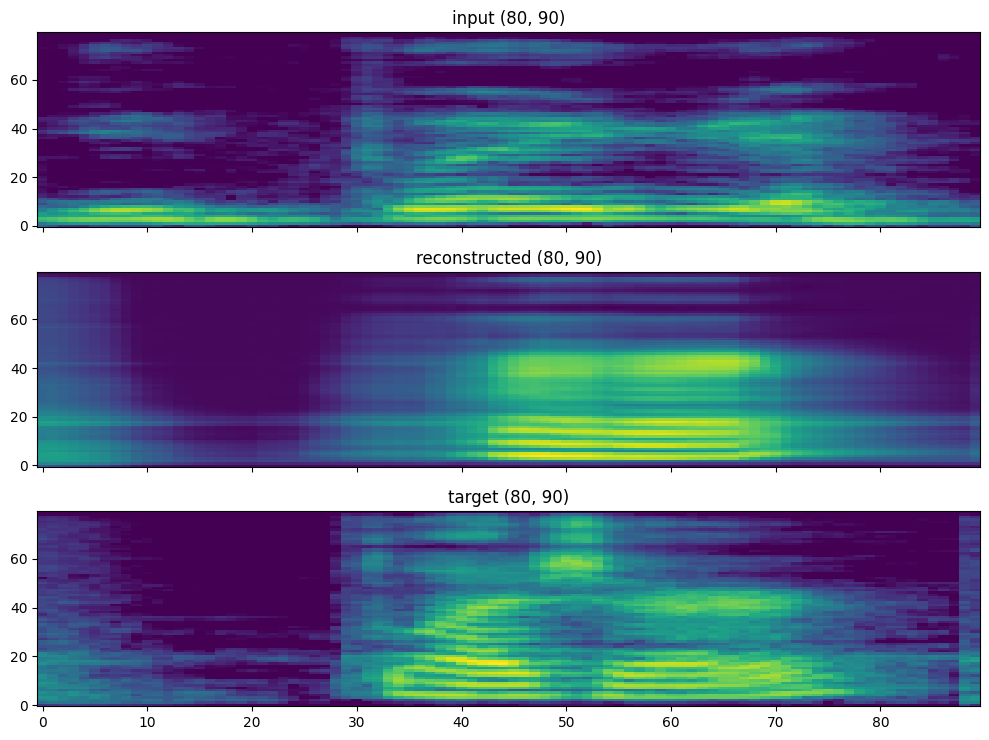

original


input_vocoded


reconstructed


target_vocoded



=== M07_B2_D1_M5  (One)
M07_B2_D1_M5_Unknown: mel L1 vs target 1.307


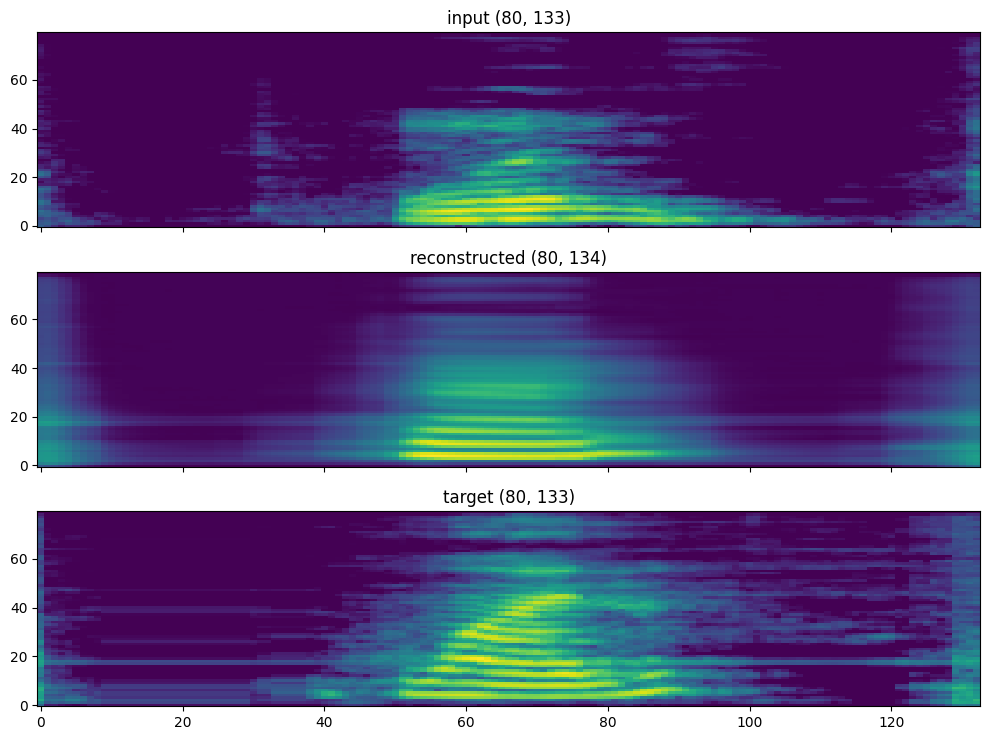

original


input_vocoded


reconstructed


target_vocoded



=== M07_B2_UW4_M5  (pennyworth)
M07_B2_UW4_M5_pennyworth: mel L1 vs target 1.291


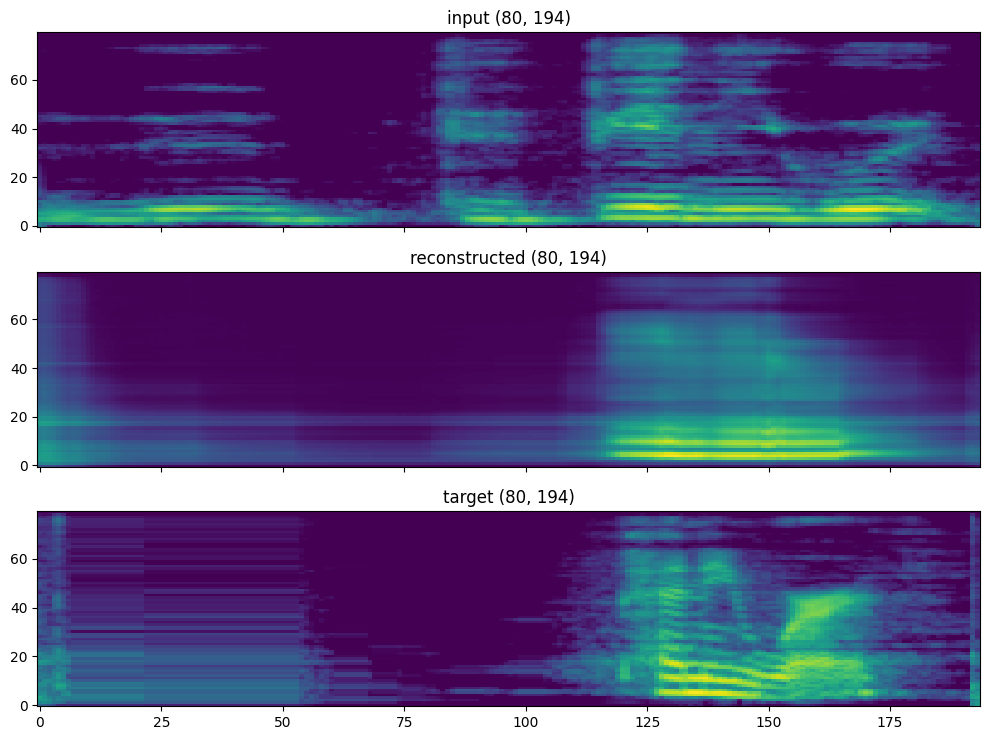

original


input_vocoded


reconstructed


target_vocoded



=== M07_B2_UW8_M5  (sharpshooter)
M07_B2_UW8_M5_sharpshooter: mel L1 vs target 2.153


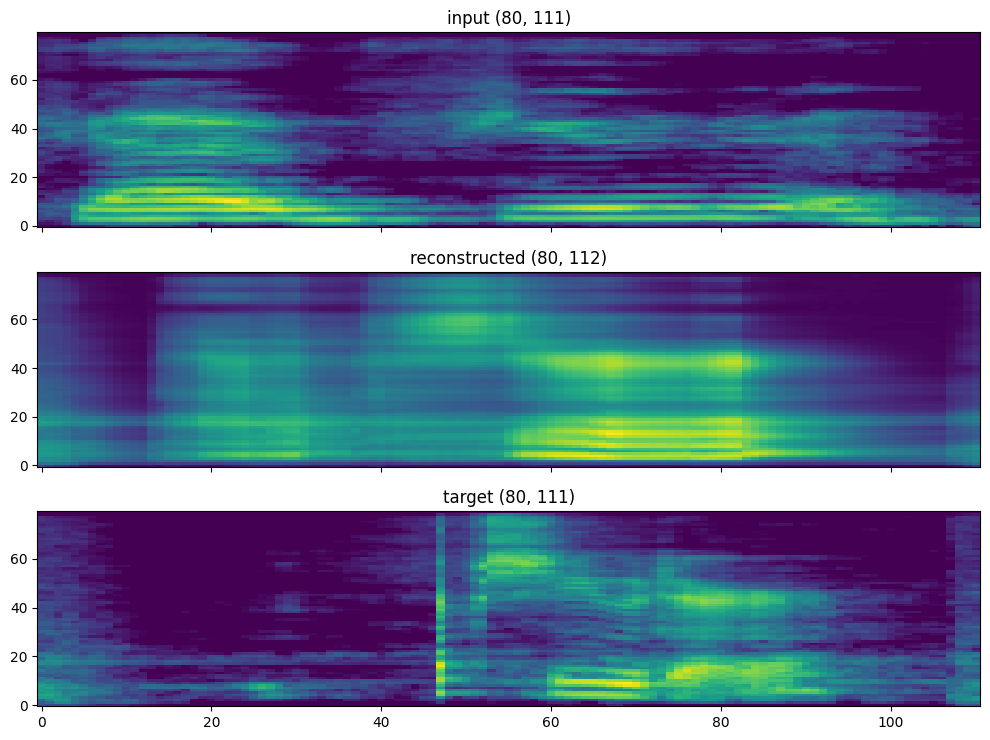

original


input_vocoded


reconstructed


target_vocoded



=== F04_B2_D5_M5  (Five)
F04_B2_D5_M5_Unknown: mel L1 vs target 1.150


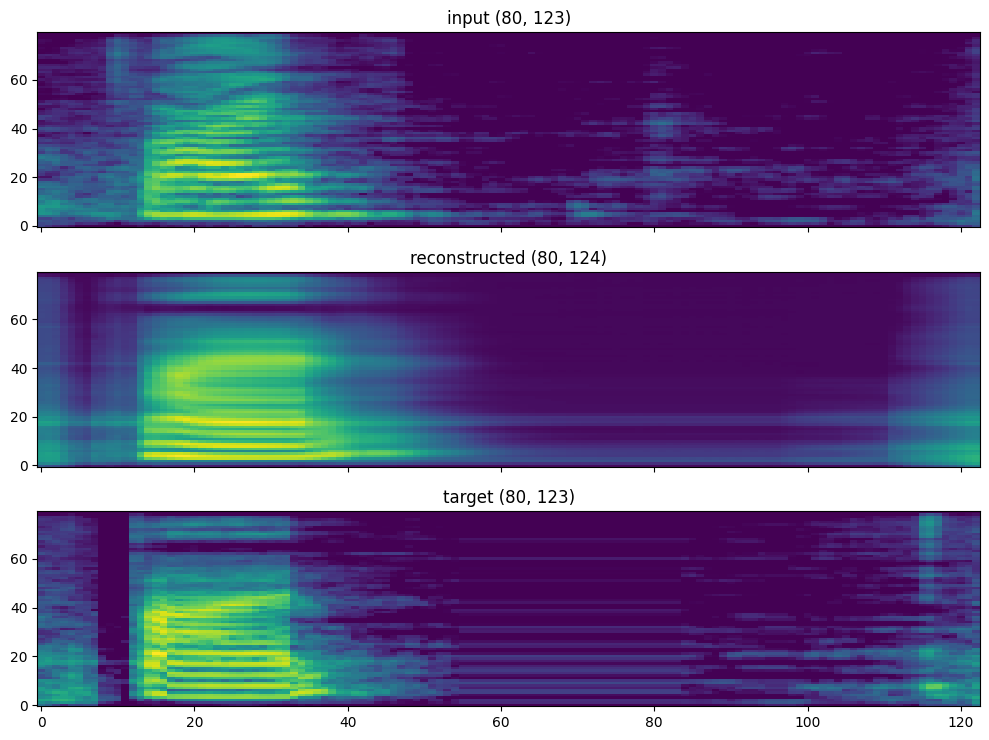

original


input_vocoded


reconstructed


target_vocoded



=== F04_B2_C6_M5  (Escape)
F04_B2_C6_M5_Unknown: mel L1 vs target 0.982


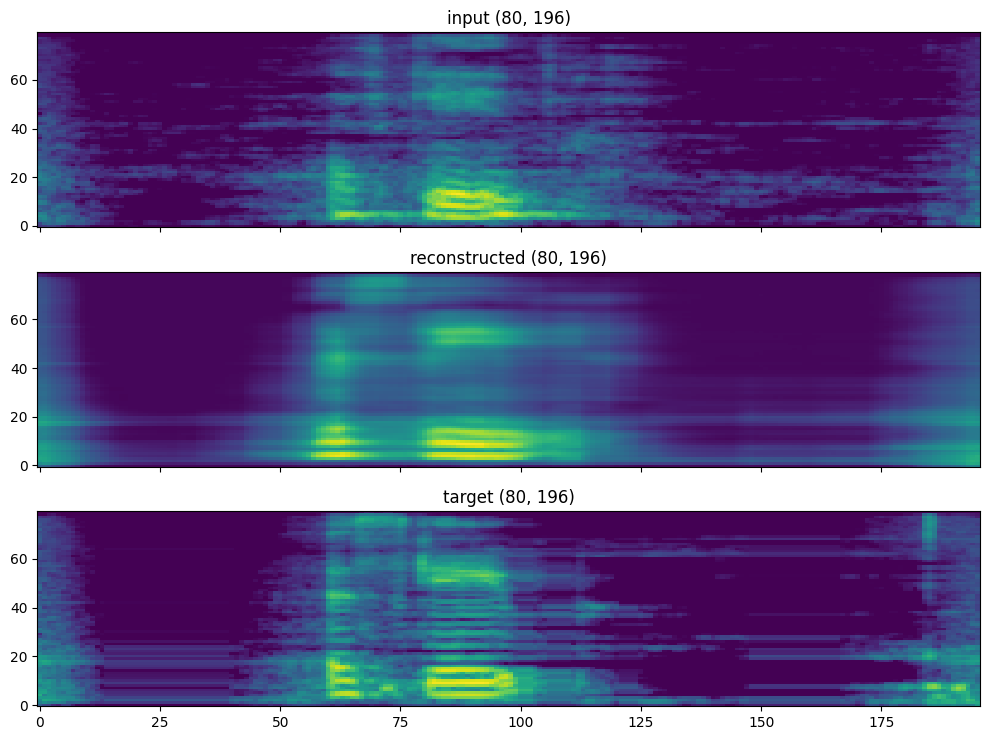

original


input_vocoded


reconstructed


target_vocoded



=== F04_B2_CW63_M5  (make)
F04_B2_CW63_M5_Unknown: mel L1 vs target 1.037


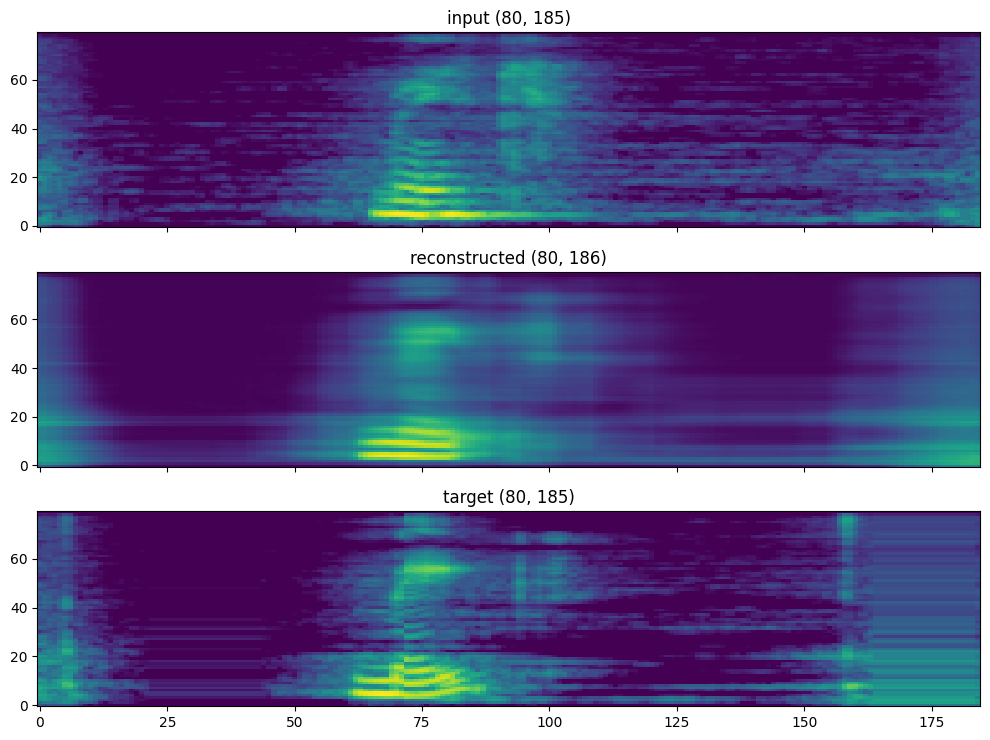

original


input_vocoded


reconstructed


target_vocoded



=== F04_B2_LX_M5  (X-ray)
F04_B2_LX_M5_Unknown: mel L1 vs target 0.835


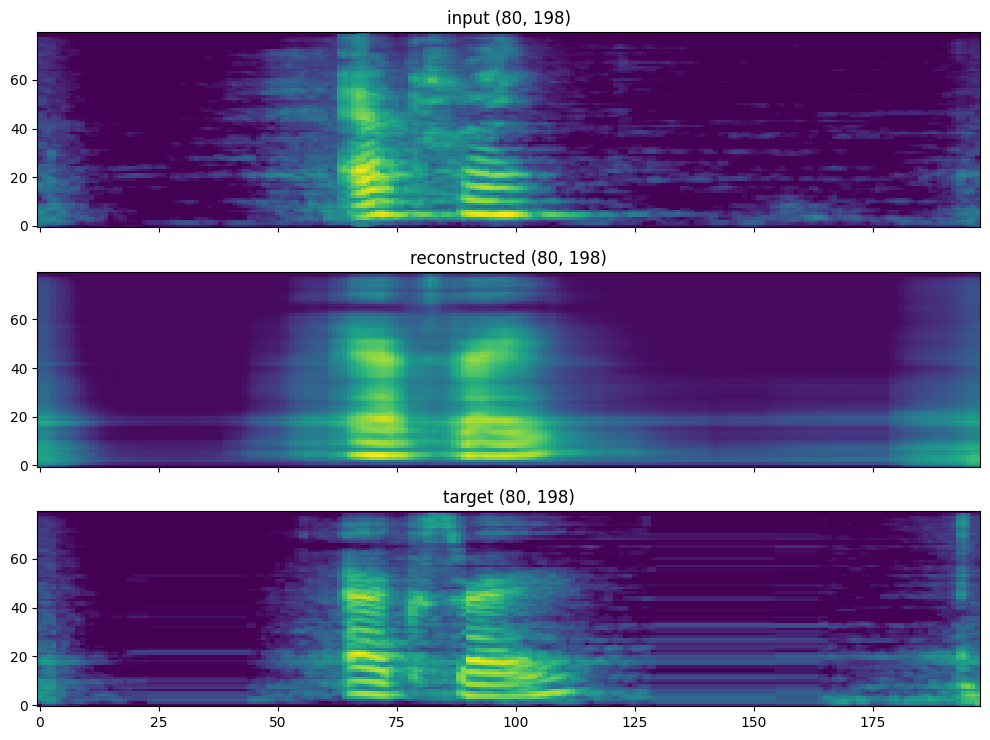

original


input_vocoded


reconstructed


target_vocoded



=== F02_B2_D8_M5  (Eight)
F02_B2_D8_M5_Unknown: mel L1 vs target 1.203


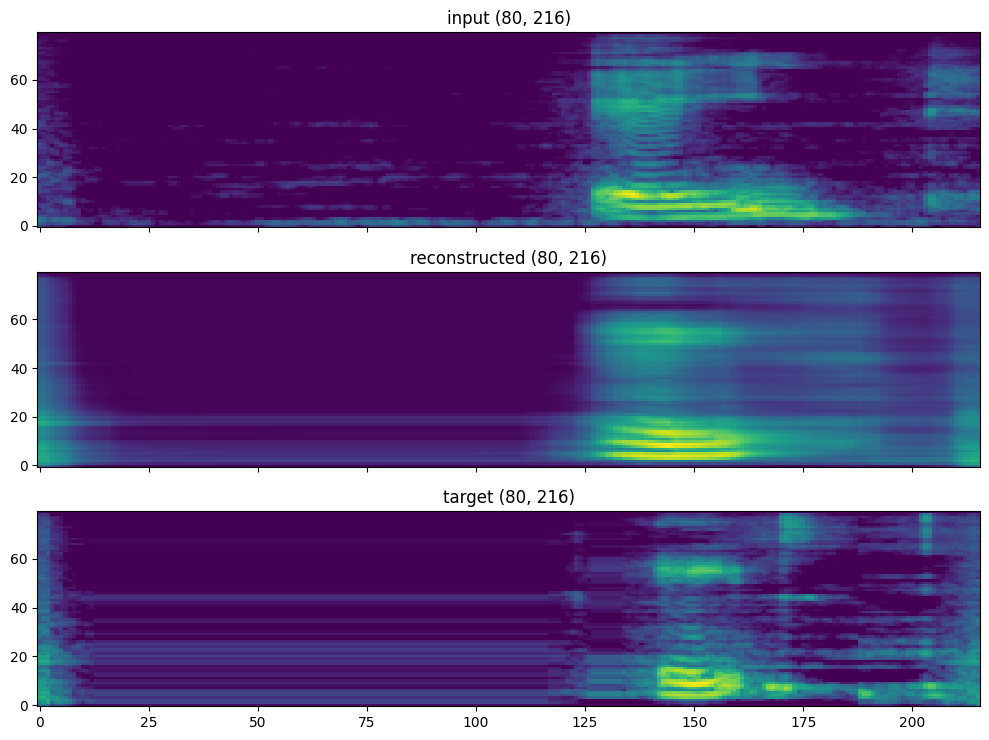

original


input_vocoded


reconstructed


target_vocoded



=== F02_B2_CW88_M5  (now)
F02_B2_CW88_M5_Unknown: mel L1 vs target 0.679


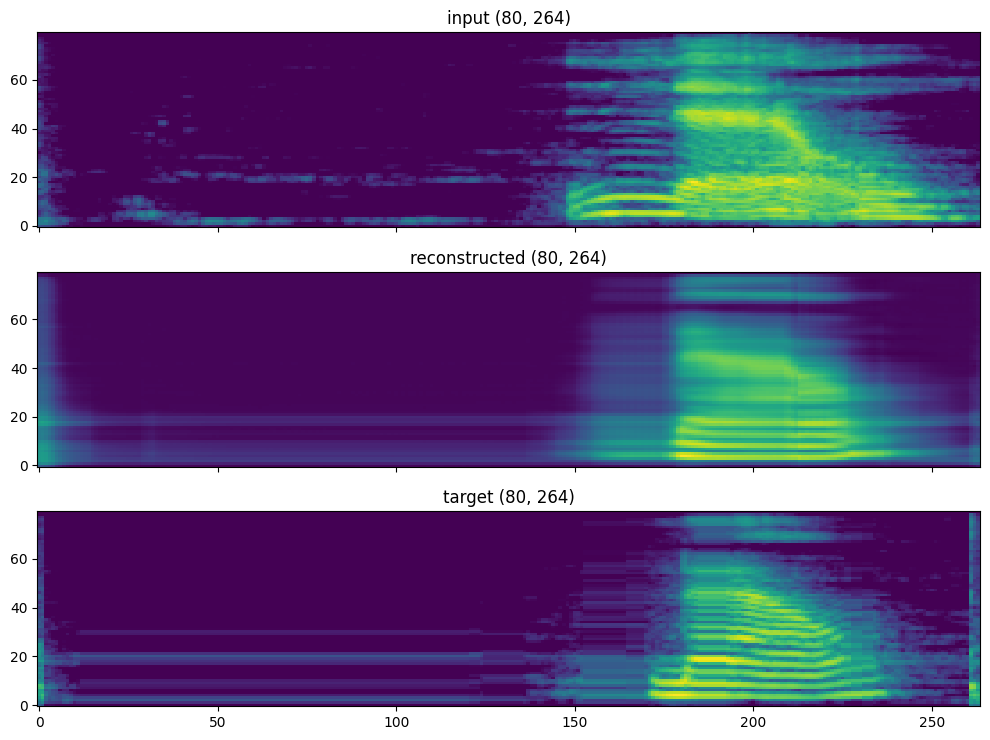

original


input_vocoded


reconstructed


target_vocoded



=== F02_B2_UW85_M5  (watches)
F02_B2_UW85_M5_watches: mel L1 vs target 0.961


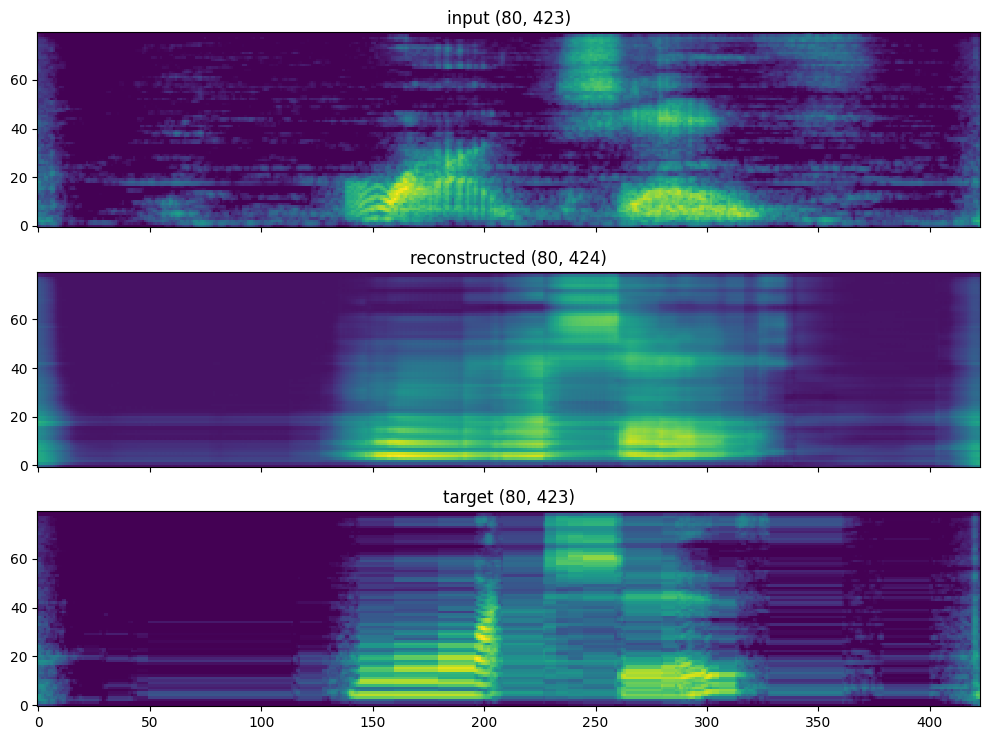

original


input_vocoded


reconstructed


target_vocoded



=== F02_B2_UW53_M5  (booth)
F02_B2_UW53_M5_booth: mel L1 vs target 1.761


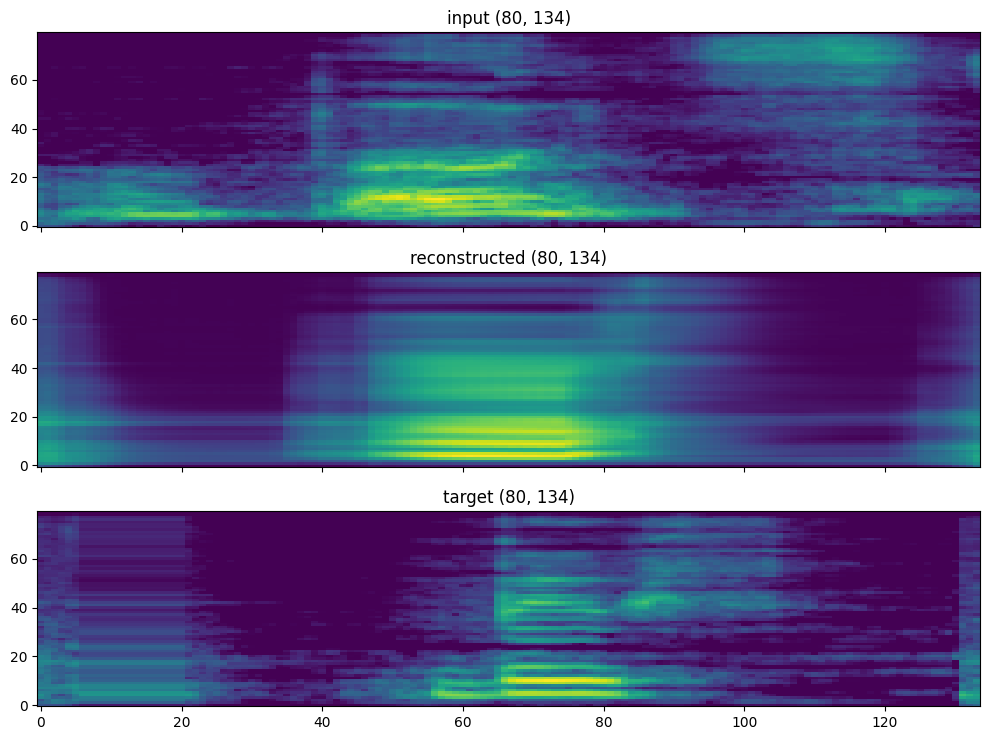

original


input_vocoded


reconstructed


target_vocoded



=== M05_B2_UW66_M5  (candlelight)
M05_B2_UW66_M5_candlelight: mel L1 vs target 1.295


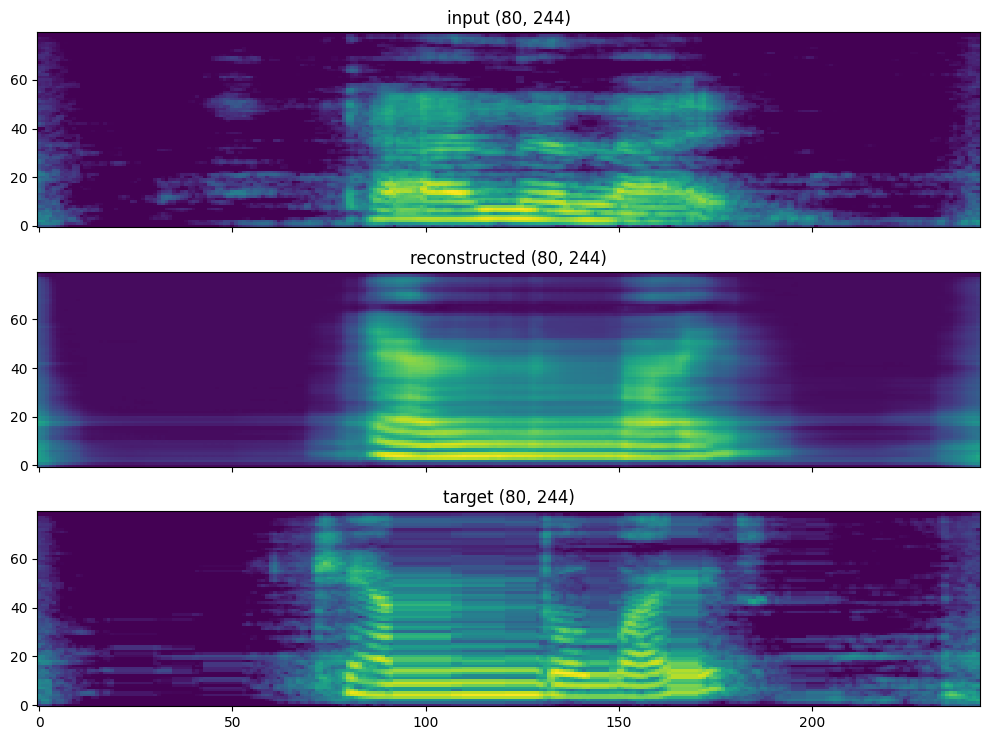

original


input_vocoded


reconstructed


target_vocoded



=== M05_B2_CW65_M5  (him)
M05_B2_CW65_M5_Unknown: mel L1 vs target 1.024


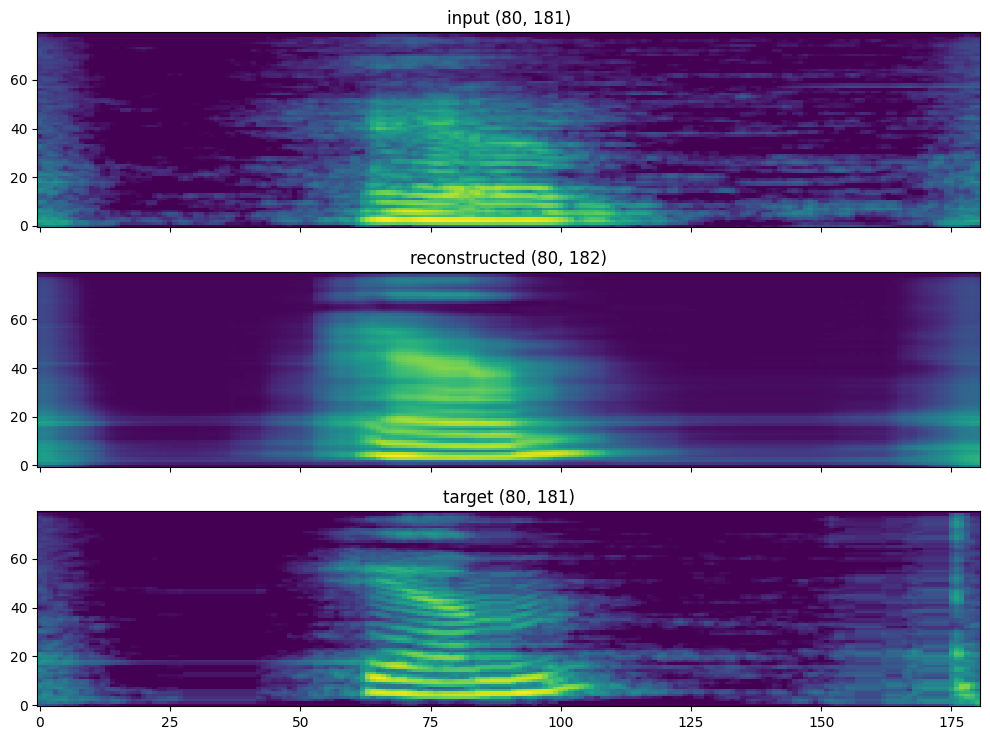

original


input_vocoded


reconstructed


target_vocoded



=== M05_B2_UW99_M5  (finger)
M05_B2_UW99_M5_finger: mel L1 vs target 0.911


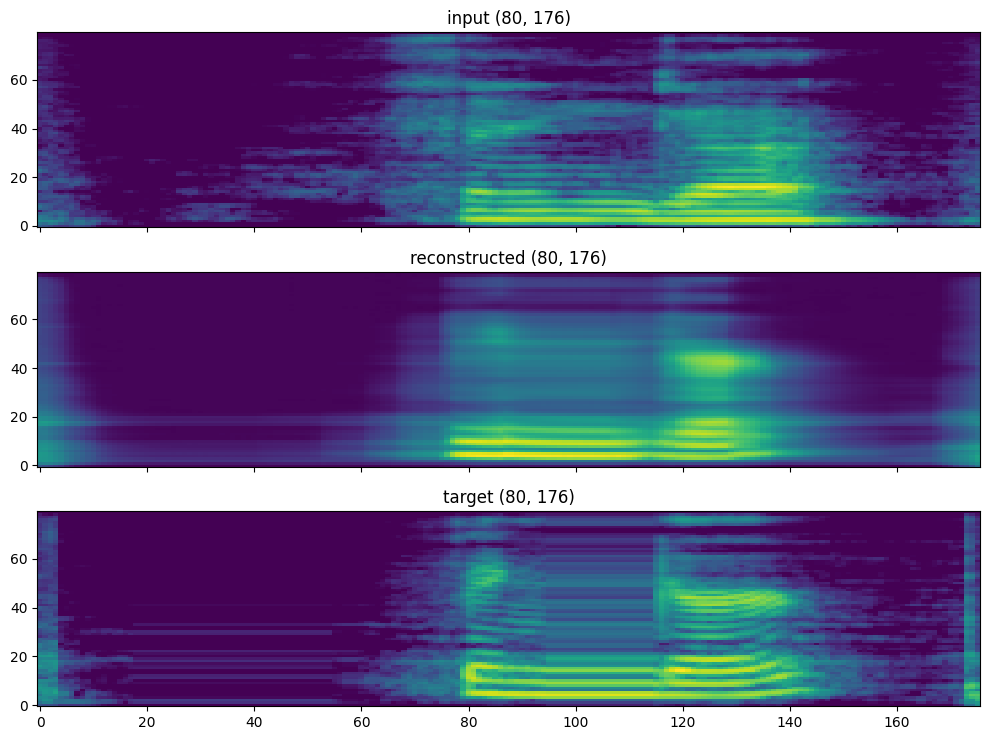

original


input_vocoded


reconstructed


target_vocoded



=== M05_B2_D6_M5  (Six)
M05_B2_D6_M5_Unknown: mel L1 vs target 1.449


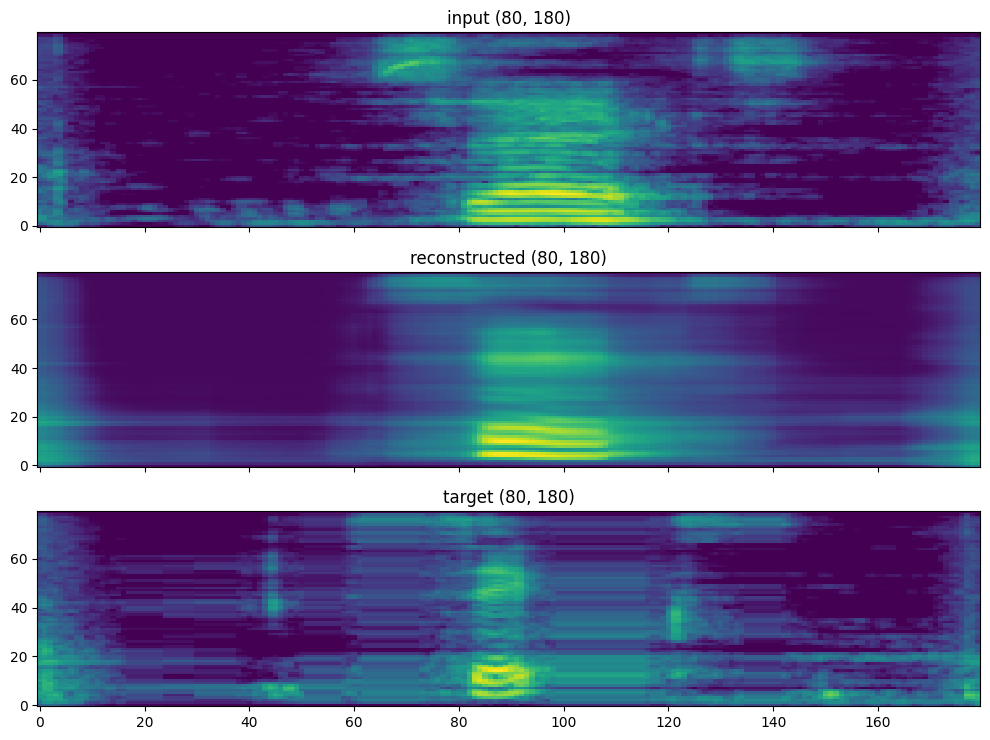

original


input_vocoded


reconstructed


target_vocoded


In [ ]:
import random
from pathlib import Path

CHECKPOINT = "checkpoints/rec2mel_best.pt"
SPEAKERS   = ["M07", "F04", "F02", "M05"]
PER_SPK    = 4
SEED       = 0                          # change for a different set
OUT        = Path("recon_random")

pipe, embs = load_pipeline(CHECKPOINT)
labels = load_word_labels(WORDLIST)
rng = random.Random(SEED)

for spk in SPEAKERS:
    files = sorted(Path(UA_PATH).rglob(f"{spk}_B2_*_M5.pt"))
    for pt in rng.sample(files, min(PER_SPK, len(files))):
        _, blk, code, _ = _parse_stem(pt.stem)
        print(f"\n=== {pt.stem}  ({label_for(labels, blk, code)})")
        reconstruct_file(pt, pipe, embs, out_dir=OUT / spk, plot=True, play=True)